# Final Iteration – Logistic Regression and Random Forest
## 1. Introduction

This notebook builds the final models of the PlaySafe project. The goal is to predict whether a LaLiga player will suffer **at least one injury in the following season**.

Compared with Iteration Zero (k-NN), this iteration:
- uses the **age of the player in each season** instead of today's age,
- adds the **injury history of the season** (number of injuries, days out, matches missed),
- trains a **logistic regression** and a **random forest** and compares them.

The cleaned dataset from `01_data_cleaning` is used as the starting point.

## 2. Load the data

The cleaned dataset created during the data-cleaning stage is loaded into the notebook. This dataset contains player information, season information, playing time, and injury records.

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/processed/laliga_cleaned.csv")
print("Shape:", df.shape)
df.head()

Shape: (3713, 14)


,player_name,date_of_birth_age,height,position,current_age_x,minutes_played,season,injury,from_date,to_date,days_out,matches_missed,injury_year,age_at_injury
0,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,2970.0,24/25,Adductor injury,2024-10-23,2024-11-23,32.0,3.0,2024.0,31.0
1,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,2970.0,24/25,Adductor tear,2024-09-30,2024-10-18,19.0,2.0,2024.0,31.0
2,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,513.0,23/24,Meniscus tear,2024-03-19,2024-04-28,41.0,6.0,2024.0,31.0
3,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,513.0,23/24,Cruciate ligament tear,2023-08-10,2024-03-31,235.0,42.0,2023.0,30.0
4,Thibaut Courtois,May 11 1992 (32),200.0,Goalkeeper,32,4920.0,22/23,Adductor pain,2023-03-26,2023-03-30,5.0,1.0,2023.0,30.0


The dataset has **3,713** rows and **14** columns. Each row is one injury record, so the same player can appear many times.

## 3. Prepare the data (One row per player-season)

The cleaned dataset has **one row per injury**, but the model needs **one row per player and season**. The rows are grouped by player and season:

- height, position and minutes are the same in every row of the group, so the first value is kept,
- `n_injuries` counts how many injuries the player had,
- `days_out` and `matches_missed` add up all the injuries of that season (0 if there was none).

In [3]:
player_season = (
    df.groupby(["player_name", "season"], as_index=False)
      .agg(
          height=("height", "first"),
          position=("position", "first"),
          date_of_birth_age=("date_of_birth_age", "first"),
          minutes_played=("minutes_played", "first"),
          n_injuries=("injury", "count"),
          days_out=("days_out", "sum"),
          matches_missed=("matches_missed", "sum"),
      )
)

# True if the player had at least one injury in that season
player_season["has_injury"] = player_season["n_injuries"] > 0

print("Shape:", player_season.shape)
player_season.head(10)

Shape: (2942, 10)


,player_name,season,height,position,date_of_birth_age,minutes_played,n_injuries,days_out,matches_missed,has_injury
0,Abde Ezzalzouli,19/20,177.0,Left Winger,Dec 17 2001 (23),160.0,0,0.0,0.0,False
1,Abde Ezzalzouli,20/21,177.0,Left Winger,Dec 17 2001 (23),1788.0,0,0.0,0.0,False
2,Abde Ezzalzouli,21/22,177.0,Left Winger,Dec 17 2001 (23),3769.0,3,25.0,2.0,True
3,Abde Ezzalzouli,22/23,177.0,Left Winger,Dec 17 2001 (23),2583.0,1,23.0,4.0,True
4,Abde Ezzalzouli,23/24,177.0,Left Winger,Dec 17 2001 (23),3016.0,0,0.0,0.0,False
5,Abde Ezzalzouli,24/25,177.0,Left Winger,Dec 17 2001 (23),3253.0,0,0.0,0.0,False
6,Abdel Abqar,18/19,188.0,Centre-Back,Mar 10 1999 (25),3394.0,0,0.0,0.0,False
7,Abdel Abqar,20/21,188.0,Centre-Back,Mar 10 1999 (25),2388.0,0,0.0,0.0,False
8,Abdel Abqar,21/22,188.0,Centre-Back,Mar 10 1999 (25),45.0,0,0.0,0.0,False
9,Abdel Abqar,22/23,188.0,Centre-Back,Mar 10 1999 (25),3700.0,0,0.0,0.0,False


The new table has **2,942** rows, one for each player and season.

### Age in each season

`current_age_x` is the age of the player **today**, so it is the same in every season. The age in each season is calculated as:
**season start year** (for example `21/22` -> 2021) minus **birth year** (from `May 11 1992 (32)` -> 1992).

In [4]:
birth_year = player_season["date_of_birth_age"].str.extract(r"(\d{4})")[0].astype(int)
player_season["season_start"] = 2000 + player_season["season"].str[:2].astype(int)
player_season["age_season"] = player_season["season_start"] - birth_year

# Check: the age of one player should grow one year per season
player_season[player_season["player_name"] == player_season["player_name"].iloc[0]]

,player_name,season,height,position,date_of_birth_age,minutes_played,n_injuries,days_out,matches_missed,has_injury,season_start,age_season
0,Abde Ezzalzouli,19/20,177.0,Left Winger,Dec 17 2001 (23),160.0,0,0.0,0.0,False,2019,18
1,Abde Ezzalzouli,20/21,177.0,Left Winger,Dec 17 2001 (23),1788.0,0,0.0,0.0,False,2020,19
2,Abde Ezzalzouli,21/22,177.0,Left Winger,Dec 17 2001 (23),3769.0,3,25.0,2.0,True,2021,20
3,Abde Ezzalzouli,22/23,177.0,Left Winger,Dec 17 2001 (23),2583.0,1,23.0,4.0,True,2022,21
4,Abde Ezzalzouli,23/24,177.0,Left Winger,Dec 17 2001 (23),3016.0,0,0.0,0.0,False,2023,22
5,Abde Ezzalzouli,24/25,177.0,Left Winger,Dec 17 2001 (23),3253.0,0,0.0,0.0,False,2024,23


The age of Abde Ezzalzouli increases by one year in each season, from **18** to **23**, so the calculation is correct.

## 4. Target variable

`has_injury_next_season` is 1 if the same player has at least one injury in the **following season**, and 0 if not. Player-seasons for which the following season is not available are removed because a target value cannot be determined for them.

In [5]:
# For each player and season, look at the season before: its answer belongs to that earlier row
next_season = player_season[["player_name", "season_start", "has_injury"]].copy()
next_season["season_start"] = next_season["season_start"] - 1
next_season = next_season.rename(columns={"has_injury": "has_injury_next_season"})

model_df = player_season.merge(next_season, on=["player_name", "season_start"], how="left")
model_df = model_df.dropna(subset=["has_injury_next_season"]).copy()
model_df["has_injury_next_season"] = model_df["has_injury_next_season"].astype(int)

print("Shape:", model_df.shape)
model_df["has_injury_next_season"].value_counts()

Shape: (2082, 13)


has_injury_next_season
0    1269
1     813
Name: count, dtype: int64

After removing these rows, the dataset has **2,082** player-seasons. There are **1,269** without an injury in the next season and **813** with an injury.

This chart helps us visualise how many player-seasons have an injury in the next season and how many do not.

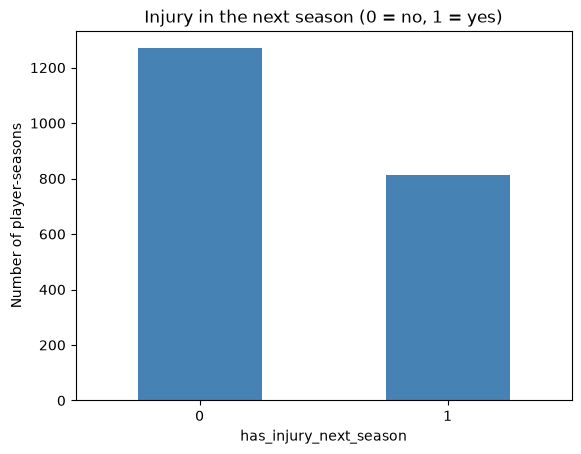

In [6]:
import matplotlib.pyplot as plt

model_df["has_injury_next_season"].value_counts().sort_index().plot(
    kind="bar", color="steelblue")
plt.title("Injury in the next season (0 = no, 1 = yes)")
plt.xlabel("has_injury_next_season")
plt.ylabel("Number of player-seasons")
plt.xticks(rotation=0)
plt.show()

We can observe that there are more cases without injury than with injury. This means that a model that always predicts "no injury" would be right most of the time, so accuracy alone is not enough and precision, recall and F1-score are also used.

## 5. Features and train-test split

The variables used to predict are:
height, position, age in the season, minutes played, number of injuries, days out and matches missed.
The player name is only an identifier, so it is not used.

Because the objective is to predict injuries in a future season, and in reality the future is predicted from the past, the data is split chronologically rather than randomly. 
The models are trained with the seasons up to 21/22, and the later seasons from 22/23 to 24/25 are kept as unseen test data.

In [7]:
numeric_features = ["height", "age_season", "minutes_played",
                    "n_injuries", "days_out", "matches_missed"]
categorical_features = ["position"]
features = numeric_features + categorical_features

train = model_df[model_df["season_start"] <= 2021]
test = model_df[model_df["season_start"] > 2021]

X_train, y_train = train[features], train["has_injury_next_season"]
X_test, y_test = test[features], test["has_injury_next_season"]

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (1669, 7)
Test set: (413, 7)


## 6. Preprocessing

Before training the models, the numerical features are scaled and the categorical `position` variable is converted into numerical values. Empty values are filled with the median for numerical variables and with the most frequent value for position.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

## 7. Train the models

Two models are trained with the same data and the same preprocessing:

- **Logistic regression**: calculates the probability of injury from a weighted sum of the variables.
- **Random forest**: many decision trees that vote together.



In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_reg = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])

random_forest = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, random_state=42)),
])

log_reg.fit(X_train, y_train)
random_forest.fit(X_train, y_train)
print("Models trained successfully.")

Models trained successfully.


## 8. Evaluation

The models predict the test seasons, which they have not seen. The metrics are:

- **Accuracy**: share of correct predictions.
- **Precision**: of the players predicted as injured, how many were really injured.
- **Recall**: of the players who were really injured, how many the model found.
- **F1-score**: balance between precision and recall.

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
for name, model in [("Logistic regression", log_reg), ("Random forest", random_forest)]:
    y_pred = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
    })

results = pd.DataFrame(results).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic regression,0.639,0.683,0.536,0.601
Random forest,0.649,0.662,0.627,0.644


The logistic regression achieved an accuracy of **63.9%**, precision of **68.3%**, recall of **53.6%** and an F1-score of **60.1%**. The random forest achieved an accuracy of **64.9%**, precision of **66.2%**, recall of **62.7%** and an F1-score of **64.4%**.

The random forest performs slightly better overall and finds more of the players who are injured the following season. The logistic regression is slightly more precise, but it misses more injured players.

In [11]:
# Reference: accuracy of a model that always predicts the most frequent class
print("Share of each class in the test set:")
print(y_test.value_counts(normalize=True).round(3))

Share of each class in the test set:
has_injury_next_season
1    0.506
0    0.494
Name: proportion, dtype: float64


The test set is balanced, with **50.6%** of player-seasons with injury and **49.4%** without injury. A model without predictive ability would therefore have an accuracy of around 50%, and both models are clearly above this value.

## 8.1 Confusion matrix

A confusion matrix shows how many predictions were correct and incorrect. The correct predictions are in the diagonal, and the other two cells are the errors: false alarms (predicted injured but not injured) and missed injuries (predicted not injured but injured).

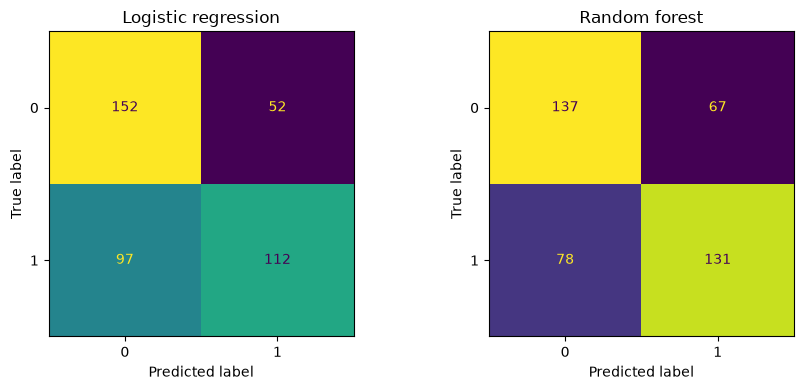

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (name, model) in zip(axes, [("Logistic regression", log_reg), ("Random forest", random_forest)]):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

The random forest missed **78** injured players, while the logistic regression missed **97**. This explains why the random forest has a higher recall.

The results of the new models are compared with the k-NN model of Iteration Zero.

In [13]:
iteration_zero = pd.DataFrame(
    {"Accuracy": [0.529], "Precision": [0.609], "Recall": [0.158], "F1-score": [0.251]},
    index=["k-NN (Iteration Zero)"],
)
iteration_zero.index.name = "Model"

pd.concat([iteration_zero, results])

,Accuracy,Precision,Recall,F1-score
Model,,,,
k-NN (Iteration Zero),0.529,0.609,0.158,0.251
Logistic regression,0.639,0.683,0.536,0.601
Random forest,0.649,0.662,0.627,0.644


## 9. Which variables matter most?

The random forest shows how much each variable was used to make decisions. A higher value means that the variable is more important.

In [14]:
names = random_forest.named_steps["preprocessor"].get_feature_names_out()
importance = pd.Series(random_forest.named_steps["model"].feature_importances_, index=names)
importance.sort_values(ascending=False).head(8).round(3)

num__minutes_played               0.304
num__height                       0.188
num__age_season                   0.164
num__days_out                     0.103
num__matches_missed               0.076
num__n_injuries                   0.051
cat__position_Central Midfield    0.014
cat__position_Centre-Forward      0.014
dtype: float64

The most important variable is minutes played (**0.304**), followed by height (**0.188**) and age in the season (**0.164**). The injury history variables (days out, matches missed and number of injuries) have a smaller importance. This list shows which variables matter, but not whether they increase or decrease the risk.

## 10. Example prediction

Finally, the trained models are used to predict a new player that they have not seen before. This step is called inference.
The data of an example player is given to the models, and they return the probability of injury in the next season. The height is in centimetres.

In [15]:
player_input = pd.DataFrame({
    "height": [180],
    "position": ["Central Midfield"],
    "age_season": [26],
    "minutes_played": [2500],
    "n_injuries": [2],
    "days_out": [45],
    "matches_missed": [7],
})

for name, model in [("Logistic regression", log_reg), ("Random forest", random_forest)]:
    probability = model.predict_proba(player_input)[0][1]
    print(f"{name}: probability of injury next season = {probability:.1%}")

Logistic regression: probability of injury next season = 76.9%
Random forest: probability of injury next season = 63.5%


The logistic regression estimates a probability of injury of **76.9%** and the random forest of **63.5%**. Both models predict that the player is more likely to be injured next season, although the probabilities are different

In [16]:
low_risk = pd.DataFrame({
       "height": [180], "position": ["Central Midfield"], "age_season": [22],
       "minutes_played": [600], "n_injuries": [0], "days_out": [0], "matches_missed": [0],
   })
for name, model in [("Logistic regression", log_reg), ("Random forest", random_forest)]:
       print(f"{name}: {model.predict_proba(low_risk)[0][1]:.1%}")

Logistic regression: 34.0%
Random forest: 39.5%


This is another example of a low risk player, the output probability of both models estimate that the player isn't going to be injured next season.

## 11. Conclusion



The final iteration trained a logistic regression and a random forest to predict whether a LaLiga player will suffer at least one injury in the following season. The process included creating one row per player-season, calculating the age of the player in each season, adding the injury history of the season, creating the target variable, splitting the data chronologically, preprocessing the variables and training and evaluating both models.

The random forest achieved an accuracy of **64.9%**, precision of **66.2%**, recall of **62.7%** and an F1-score of **64.4%**, and the logistic regression achieved an accuracy of **63.9%**, precision of **68.3%**, recall of **53.6%** and an F1-score of **60.1%**. The test set is balanced (**50.6%** with injury), so both models are clearly better than a model without predictive ability. The random forest finds more of the injured players (it missed **78** compared with **97** for the logistic regression), so it is the better option if the aim is to identify players at risk. Compared with Iteration Zero, where the k-NN model had a recall of **15.8%**, both new models find many more injured players. The most important variables were minutes played, height and age in the season.

The results have some limitations. The models use default settings and have not been tuned. About 100 values of `matches_missed` are missing and are counted as 0, and a missing injury is interpreted as no injury. The test set has only **413** rows, and the same players appear in the training and test sets, which can make the model recognise players instead of learning general patterns (for example, height is the second most important variable). In future iterations, hyperparameter tuning, variables from the previous season and other models could be tested to improve the results.

In [17]:
import joblib, os
os.makedirs("../models", exist_ok=True)
joblib.dump(random_forest, "../models/random_forest.joblib")
joblib.dump(log_reg, "../models/log_reg.joblib")
test.to_csv("../data/processed/test_set.csv", index=False)